In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2-4*x+5

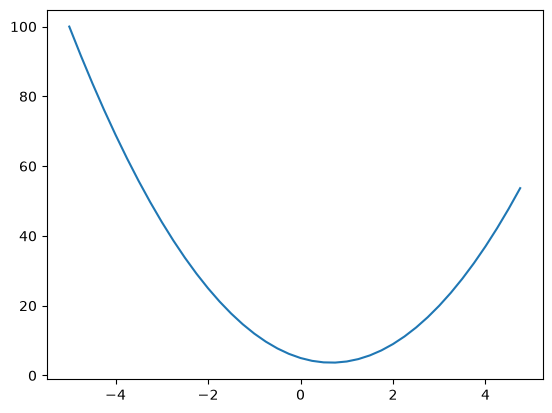

In [3]:
xs=np.arange(-5,5,0.25)
ys=f(xs)
ys
plt.plot(xs,ys)

In [4]:
h=0.00000001
x=5
derivative= (f(x+h)-f(x))/h
derivative

26.000000730164174

In [5]:
a=5
b=2
c=9
d1=a*b+c
h=0.0001
a+=h
d2=a*b+c
print('d1',d1)
print('d2',d2)
print('slope', (d2-d1)/h)

d1 19
d2 19.0002
slope 1.9999999999953388


In [59]:
import math
class Value:
    def __init__(self, data, _children=(), _op='',label=''):       
        self.data=data
        self.grad=0.
        self._backward=lambda:None
        self._children=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
    def __add__(self,other):
        other= other if isinstance(other,Value) else Value(other)
        sum=Value(self.data+other.data,(self,other),'+')
        def _backward():
            self.grad+=1.0*sum.grad
            other.grad+=1.0*sum.grad
        sum._backward=_backward
        return sum
    def __radd__(self,other):
        return self+other
    def __mul__(self,other):
        other= other if isinstance(other,Value) else Value(other)
        mul=Value(self.data*other.data,(self,other),'*')
        def _backward():
            self.grad+=other.data*mul.grad
            other.grad+=self.data*mul.grad
        mul._backward=_backward
        return mul
    def __rmul__(self,other):
        return self*other
    def __pow__(self,other):
        assert isinstance(other,(int,float)), "only supporting int/float powers for now"
        pow=Value(self.data**other,(self,),f'**{other}')
        def _backward():
            self.grad+=other*self.data**(other-1)*pow.grad
        pow._backward=_backward
        return pow
    def __neg__(self):
        return self*-1
    def __sub__(self,other):
        return self+(-other)
    def exp(self):
        x=self.data
        out=Value(math.exp(x),(self,),'exp')
        def _backward():
            self.grad+=out.data*out.grad
        out._backward=_backward
        return out
    def __truediv__(self,other):
        return self*other**-1
    def tanh(self):
        n=self.data
        t=(math.exp(2*n)-1)/(math.exp(2*n)+1)
        out=Value(t,(self,),'tanh')
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out
    def backward(self):
        topo=[]
        visited=set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._children:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad=1.0
        for node in reversed(topo):
            node._backward()
a=Value(2.0,label='a')
b=Value(-3.0,label='b')
c=Value(10.0,label='c')
e=a*b;e.label='e'
d=e+c;d.label='d'
f=Value(-2.0,label='f')
L=d*f;L.label='L'
d

Value(data=4.0)

In [7]:
from graphviz import Digraph
def trace(root):
    # build a set of all nodes and edges
    nodes,edges=set(),set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._children:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes,edges

def draw_dot(root):
    dot=Digraph(format='svg',graph_attr={'rankdir':'LR'}) # LR=left to right
    nodes,edges=trace(root)
    for n in nodes:
        uid=str(id(n))
        # for any value in the graph,create a rectangular ('record') node for it
        dot.node(name=uid,label="{ %s | data %.4f | grad %.4f }" % (n.label,n.data,n.grad,),shape='record')
        if n._op:
            # If this value is a result of some operation, create an op node for it
            dot.node(name=uid+n._op,label=n._op)
            # and connect this node to it
            dot.edge(uid+n._op,uid)
    for n1,n2 in edges:
        #Connect n1 to the op node of n2
        dot.edge(str(id(n1)),str(id(n2))+n2._op)
    return dot

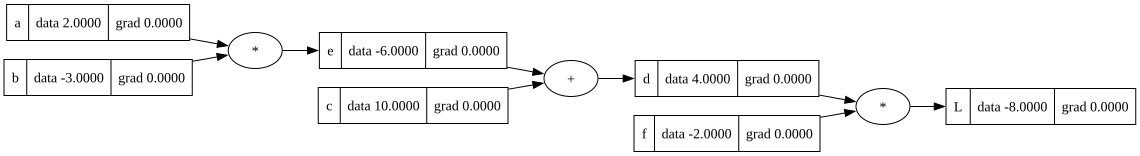

In [8]:
draw_dot(L)

In [9]:
def lol():
    h=0.0001
    a=Value(2.0,label='a')
    b=Value(-3.0,label='b')
    c=Value(10.0,label='c')
    e=a*b;e.label='e'
    d=e+c;d.label='d'
    f=Value(-2.0,label='f')
    L=d*f;L.label='L'
    L1=L.data

    a=Value(2.0,label='a')
    b=Value(-3.0,label='b')
    c=Value(10.0,label='c')
    e=a*b;e.label='e'
    d=e+c;d.label='d'
    f=Value(-2.0,label='f')
    L=d*f;L.label='L'
    L2=L.data

    print((L2-L1)/h)
lol()

0.0


In [10]:
L.grad=1.0
d.grad=-2.0
f.grad=4.0
e.grad=-2.0
c.grad=-2.0
a.grad=6.0
b.grad=-4.0

In [11]:
a.data+= 0.001*a.grad
b.data+= 0.001*b.grad
c.data+= 0.001*c.grad
f.data+= 0.001*f.grad
e=a*b
d=e+c
L=d*f


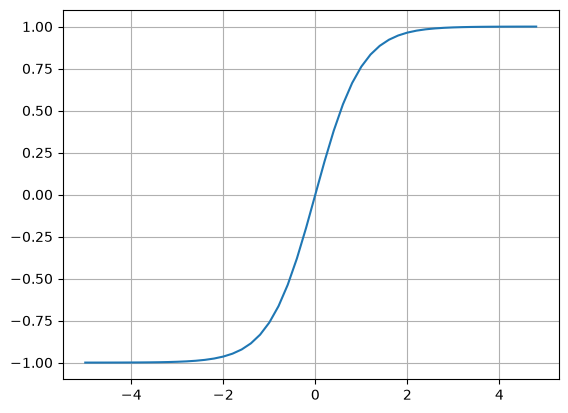

In [12]:
plt.plot(np.arange(-5,5,0.2),np.tanh(np.arange(-5,5,0.2)));plt.grid();

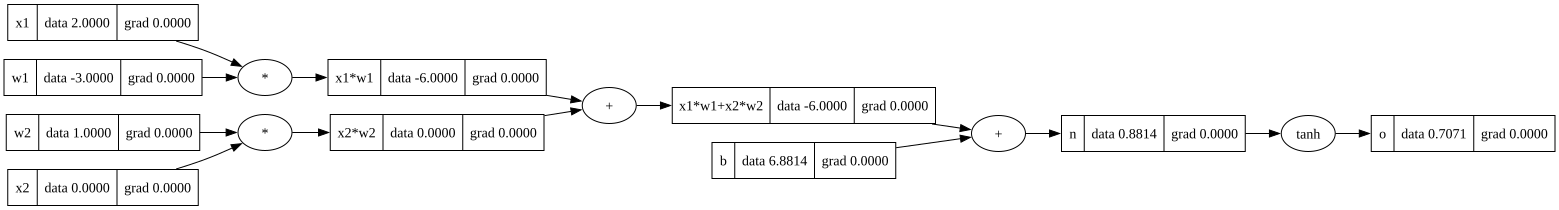

In [13]:
#inputs x1,x2
x1=Value(2.0,label='x1')
x2=Value(0.0,label='x2')
# weights w1,w2
w1=Value(-3.0,label='w1')
w2=Value(1.0,label='w2')
# bias b of the neuron
b=Value(6.8813735870195432,label='b')
x1w1=x1*w1;x1w1.label='x1*w1'
x2w2=x2*w2;x2w2.label='x2*w2'
x1w1x2w2=x1w1+x2w2;x1w1x2w2.label='x1*w1+x2*w2'
n=x1w1x2w2+b;n.label='n'
# f=1.0/(1.0+np.exp(-n));f.label='f'
o=n.tanh();o.label='o'
draw_dot(o)

In [14]:
# o.grad=1.0
# n.grad=1.0-o.data**2
# x1w1x2w2.grad=n.grad
# b.grad=n.grad
# x2w2.grad=x1w1x2w2.grad
# x1w1.grad=x1w1x2w2.grad
# x2.grad=w2.data*x2w2.grad
# w2.grad=x2.data*x2w2.grad
# w1.grad=x1.data*x1w1.grad
# x1.grad=w1.data*x1w1.grad

In [15]:

o.grad=1.0
o._backward()
n._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()


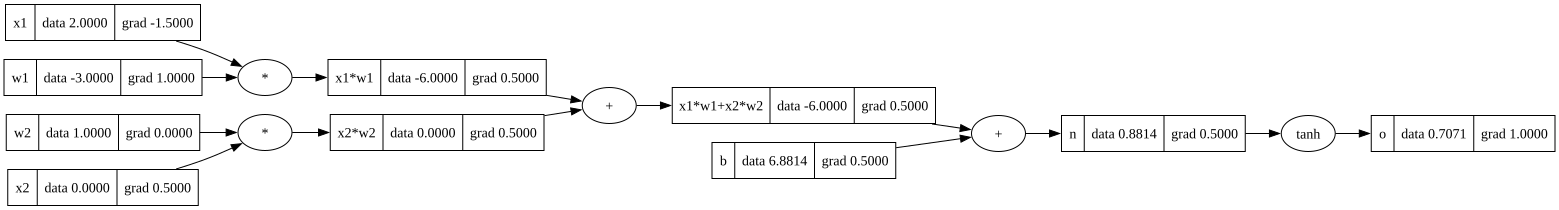

In [16]:
draw_dot(o)

In [17]:
o.backward()

In [18]:
# for node in reversed(topo):
    # node._backward()

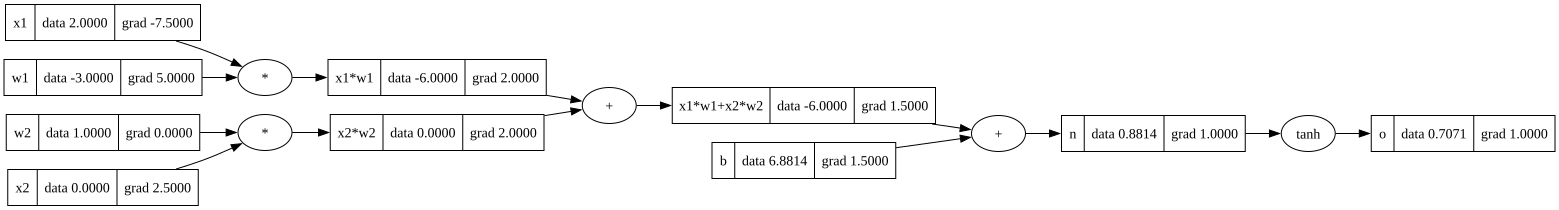

In [19]:
draw_dot(o)

# Bug

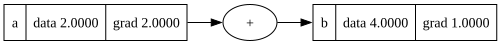

In [20]:
a=Value(2.0,label='a')
b=a+a; b.label='b'
b.backward()
draw_dot(b)

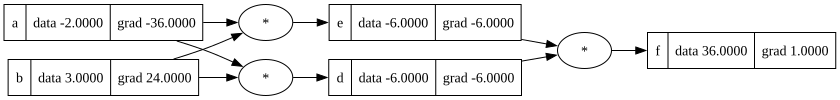

In [21]:
a=Value(-2.0,label='a')
b=Value(3.0,label='b')
d=a*b; d.label='d'
e=a*b; e.label='e'
f=d*e; f.label='f'
f.backward()
draw_dot(f)

In [22]:
#inputs x1,x2
x1=Value(2.0,label='x1')
x2=Value(0.0,label='x2')
# weights w1,w2
w1=Value(-3.0,label='w1')
w2=Value(1.0,label='w2')
# bias b of the neuron
b=Value(6.8813735870195432,label='b')
x1w1=x1*w1;x1w1.label='x1*w1'
x2w2=x2*w2;x2w2.label='x2*w2'
x1w1x2w2=x1w1+x2w2;x1w1x2w2.label='x1*w1+x2*w2'
n=x1w1x2w2+b;n.label='n'
# f=1.0/(1.0+np.exp(-n));f.label='f'
o=n.tanh();o.label='o'
o.backward()


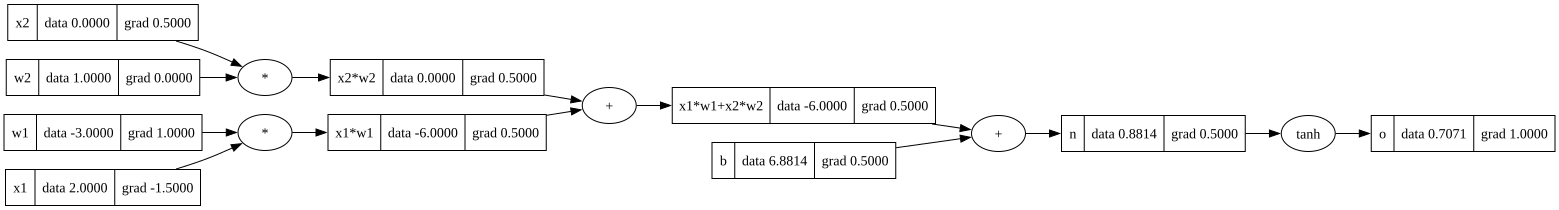

In [23]:
draw_dot(o)

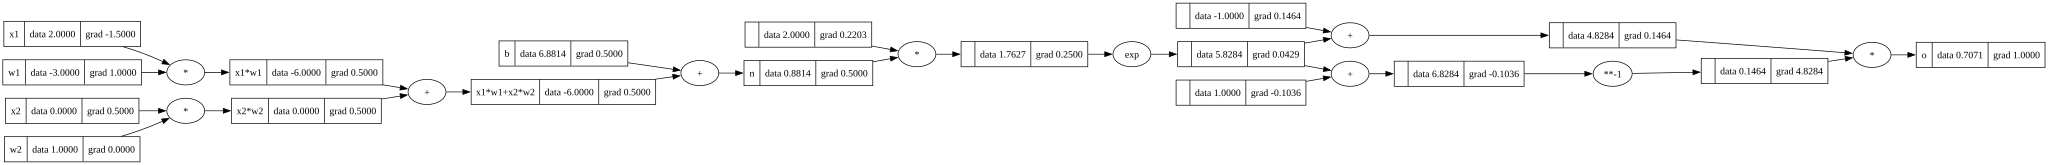

In [24]:
#inputs x1,x2
x1=Value(2.0,label='x1')
x2=Value(0.0,label='x2')
# weights w1,w2
w1=Value(-3.0,label='w1')
w2=Value(1.0,label='w2')
# bias b of the neuron
b=Value(6.8813735870195432,label='b')
x1w1=x1*w1;x1w1.label='x1*w1'
x2w2=x2*w2;x2w2.label='x2*w2'
x1w1x2w2=x1w1+x2w2;x1w1x2w2.label='x1*w1+x2*w2'
n=x1w1x2w2+b;n.label='n'
# f=1.0/(1.0+np.exp(-n));f.label='f'
e=(2*n).exp()
o=(e-1)/(e+1);o.label='o'
o.backward()
draw_dot(o)

In [26]:
import torch
x1=torch.Tensor([2.0]).double(); x1.requires_grad=True
x2=torch.Tensor([0.0]).double(); x2.requires_grad=True
w1=torch.Tensor([-3.0]).double(); w1.requires_grad=True
w2=torch.Tensor([1.0]).double(); w2.requires_grad=True
b=torch.Tensor([6.8813735870195432]).double(); b.requires_grad=True
n=x1*w1+x2*w2+b
o=torch.tanh(n)
print(o.data.item())
o.backward()
print('----')
print('x2',x2.grad.item())
print('w2',w2.grad.item())
print('x1',x1.grad.item())
print('w1',w1.grad.item())


0.7071066904050358
----
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [29]:
x2.grad

tensor([0.5000], dtype=torch.float64)

In [66]:
import random
class Neuron:
    def __init__(self,nin):
        self.w=[Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(random.uniform(-1,1))
    def __call__(self,x):
        #w*x+b
        act=sum((wi*xi for wi,xi in zip(self.w,x)),self.b)
        out=act.tanh()
        return out
    def parameters(self):
        return self.w+[self.b]
class Layer:
    def __init__(self,nin,nout):
        self.neurons=[Neuron(nin) for _ in range(nout)]
    def __call__(self,x):
        out=[n(x) for n in self.neurons]
        return out[0] if len(out)==1 else out
    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
        # # params=[]
        # # for neuron in self.neurons:
        #     ps=neuron.parameters()
        #     params.extend(ps)
        # return params
class MLP:
    def __init__(self,nin,nouts):
        sz=[nin]+nouts
        self.layers=[Layer(sz[i],sz[i+1]) for i in range(len(nouts))]
    def __call__(self,x):
        for layer in self.layers:
            x=layer(x)
        return x
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]
x=[2.0,3.0,-1.0]
n=MLP(3,[4,4,1])
n(x)

Value(data=-0.8797180699052128)

In [68]:
len(n.parameters())

41

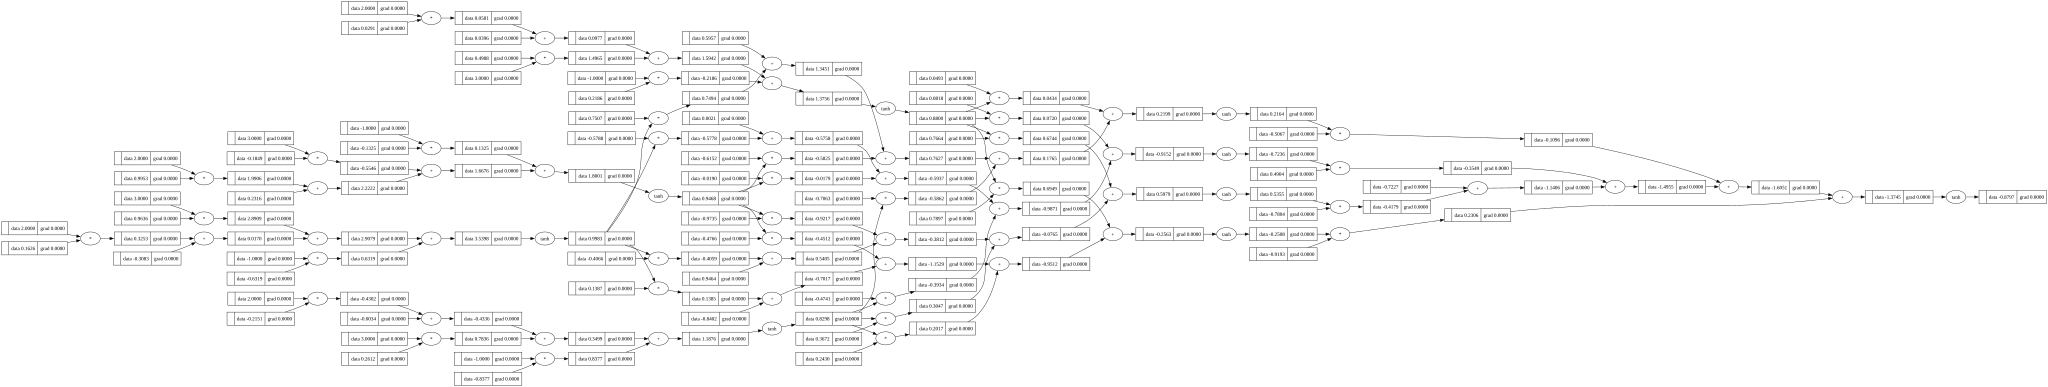

In [69]:
draw_dot(n(x))

In [85]:
xs=[
    [2.0,3.0,-1.0],
    [3.0,-1.0,0.5],
    [0.5,1.0,1.0],
    [1.0,1.0,-1.0],
]
ys=[1.0,-1.0,-1.0,1.0] # desired targets
# ypred=[n(x) for x in xs]
# ypred

In [71]:
loss = sum((yout - ygt) ** 2 for ygt, yout in zip(ys, ypred))
loss

Value(data=9.007626632512736)

In [72]:
loss.backward()

In [73]:
n.layers[0].neurons[0].w[0].grad

-0.48362467916190044

In [74]:
n.layers[0].neurons[0].w[0].data

0.1626494598773276

# Gradient Descent

In [77]:
for p in n.parameters():
    p.data+= -0.01*p.grad

In [78]:
n.layers[0].neurons[0].w[0].data

0.1674857066689466

In [79]:
ypred=[n(x) for x in xs]
loss = sum((yout - ygt) ** 2 for ygt, yout in zip(ys, ypred))
loss

Value(data=8.19996796070105)

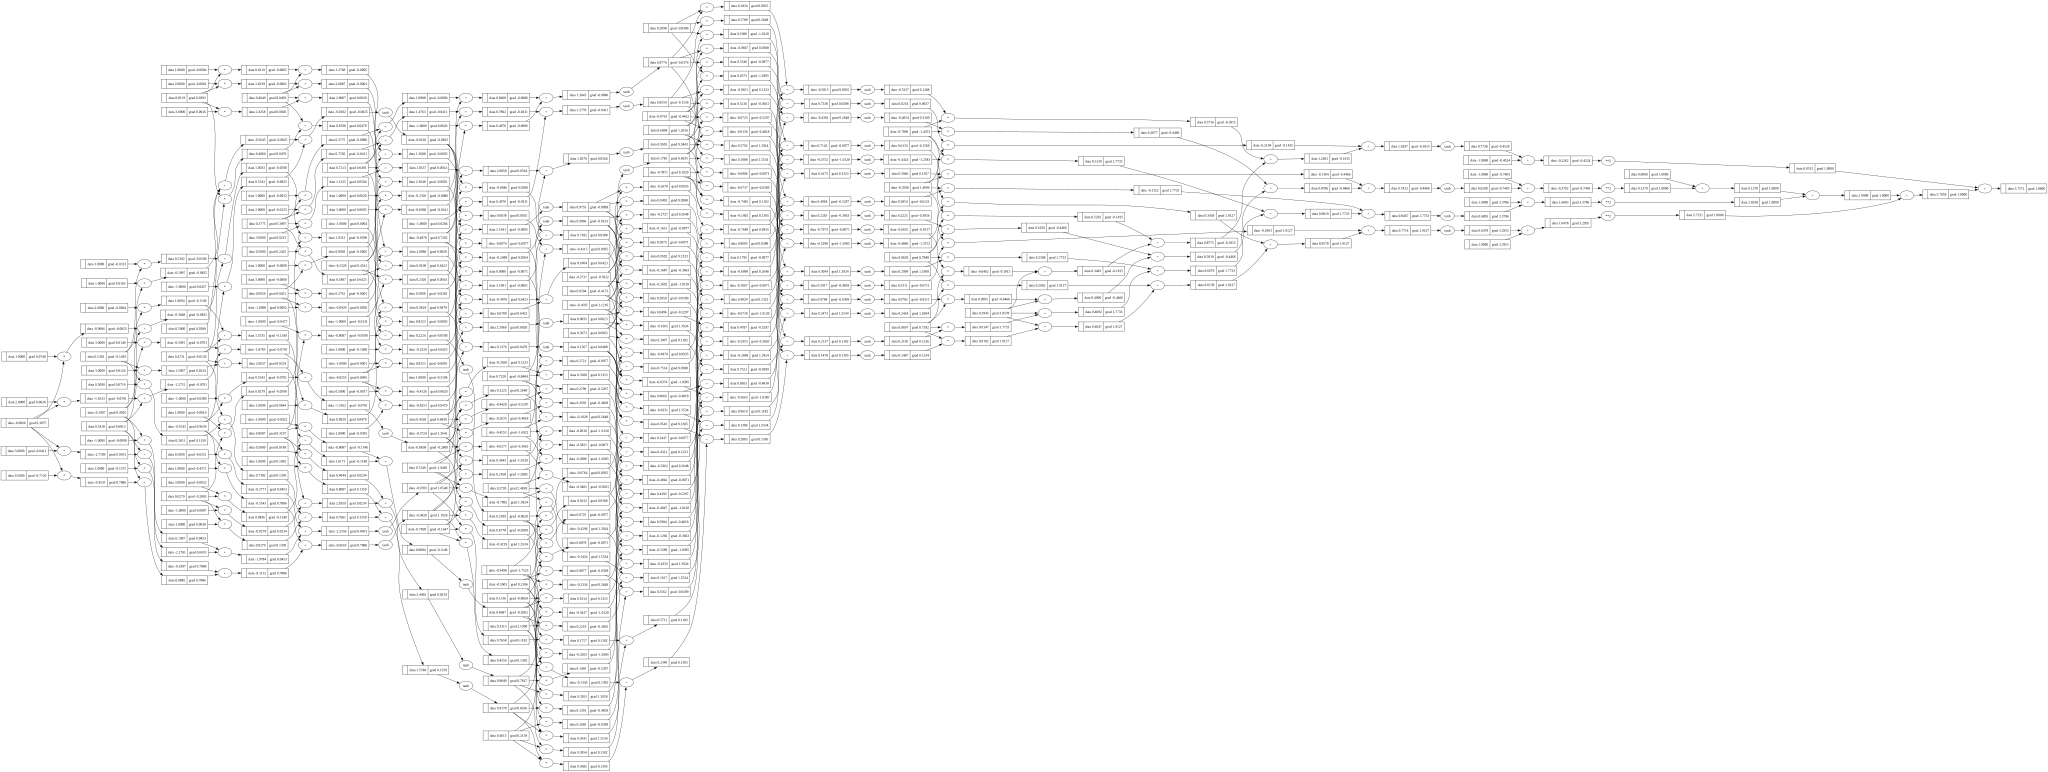

In [65]:
draw_dot(loss)

In [80]:
ypred

[Value(data=-0.8324787516923673),
 Value(data=0.46990875413065636),
 Value(data=-0.7334240526375934),
 Value(data=-0.6156407719895319)]

In [94]:
for k in range(20):
    #forward pass
    ypred=[n(x) for x in xs]
    loss = sum((yout - ygt) ** 2 for ygt, yout in zip(ys, ypred))
    #backward pass
    for p in n.parameters():
        p.grad=0.0
    loss.backward()
    #update 
    for p in n.parameters():
        p.data += -0.05 * p.grad
    print(k,loss.data)

0 1.4875972396845343e-11
1 1.4875972296645175e-11
2 1.487597219730142e-11
3 1.487597209710125e-11
4 1.4875971996901087e-11
5 1.4875971896700922e-11
6 1.4875971796500754e-11
7 1.487597169630059e-11
8 1.4875971596100424e-11
9 1.487597149590026e-11
10 1.4875971396556504e-11
11 1.4875971296356343e-11
12 1.4875971196156178e-11
13 1.4875971095956013e-11
14 1.487597099575585e-11
15 1.487597089555569e-11
16 1.4875970795355525e-11
17 1.4875970695155363e-11
18 1.4875970595811615e-11
19 1.4875970495611453e-11


In [89]:
ypred

[Value(data=0.9999961430635801),
 Value(data=-0.9999999998879682),
 Value(data=-0.9999999984557161),
 Value(data=0.9999999955773421)]